In [39]:
import jax
import jax.numpy as jnp
import jax.random as jr
from jax import config
from jaxtyping import (
    PyTree,
    Array,
    Float,
    Int,
    install_import_hook,
)

config.update("jax_enable_x64", True)

with install_import_hook("gpjax", "beartype.beartype"):
    import gpjax as gpx
from gpjax.kernels.computations import DenseKernelComputation

from tqdm import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



In [40]:
########
# Data #
########

def get_datasets(num_train, num_test, rnd_key):
    df_raw = pd.read_csv('../RainGarden.csv')
    df_f = df_raw.iloc[7000:10000]

    # convert to unix time (and reset by start time) and add zero dimension
    xs = df_f['Time']
    xs = (pd.to_datetime(xs, format='%m/%d/%y %H:%M').astype(int) // 1e9).values
    xs = xs - xs[0]
    xs = xs.astype(float)
    xs = xs[:, None]
    xs = add_zeros_dim(xs)

    yss = []
    for i in range(1, 4):
        yss.append(df_f[f'wfv_{i}'].values[:, None])

    # split the data into training and test sets (jax random)
    rnd_key, subkey = jr.split(rnd_key)
    idx = np.array(jr.permutation(subkey, np.arange(xs.shape[0])))
    idx_train = idx[:num_train]
    idx_test = idx[num_train:num_train + num_test]

    xs_train = jnp.array(xs[idx_train])
    xs_test = jnp.array(xs[idx_test])

    dataset_dict = {
        'train': [],
        'test': []
    }
    for ys in yss:
        ys_train = jnp.array(ys[idx_train])
        ys_test = jnp.array(ys[idx_test])
        dataset_dict['train'].append(gpx.Dataset(xs_train, ys_train))
        dataset_dict['test'].append(gpx.Dataset(xs_test, ys_test))
    
    return dataset_dict, rnd_key

def add_zeros_dim(xs):
    zeros = np.zeros((xs.shape[0], 1))
    return np.concatenate([xs, zeros], axis=1)

def add_ones_dim(xs):
    ones = np.ones((xs.shape[0], 1))
    return np.concatenate([xs, ones], axis=1)


In [41]:
#######
# Vis #
#######

def format_data_to_plot(D):
    x = D.X[:, 0]
    y = D.y

    # need to sort the data for plotting
    argsort = np.argsort(x)
    x = x[argsort]
    y = y[argsort]

    return x, y

def format_standard_plot(ax):
    ax.set_xlabel("Elapsed Time (s)")
    ax.set_ylabel("Soil Moisture Content (m$^3$ m$^{-3}$)")
    ax.set_ylim([0, 60])

def format_derivative_plot(ax):
    ax.set_xlabel("Elapsed Time (s)")
    ax.set_ylabel("Soil Moisture Content Derivative (m$^3$ m$^{-3}$ t$^{-1}$)")
    # ax.set_ylim([-0.5, 0.5])


In [42]:
import jax.numpy as jnp
from jaxtyping import Float
import tensorflow_probability.substrates.jax as tfp

from gpjax.kernels.stationary.base import StationaryKernel
from gpjax.kernels.stationary.utils import squared_distance
from gpjax.typing import (
    Array,
    ScalarFloat,
)

class dxRBF(StationaryKernel):
    """
    The gradient of the RBF kernel wrt x, returning a D-dimensional vector.
    dxRBF(x, y)[i] = d/dx_i [RBF(x, y)].
    """

    name: str = "dxRBF"

    def __call__(self, x: Float[Array, " D"], y: Float[Array, " D"]) -> Float[Array, " D"]:
        # 1) Extract/scale inputs
        x_ = self.slice_input(x) / self.lengthscale.value  # shape (D,)
        y_ = self.slice_input(y) / self.lengthscale.value  # shape (D,)

        sqdist = squared_distance(x_, y_)
        base_rbf = self.variance.value * jnp.exp(-0.5 * sqdist)

        diff = (self.slice_input(x) - self.slice_input(y))  # shape (D,)

        c = -1.0 / (self.lengthscale.value ** 2)
        grad = c * diff * base_rbf  # shape (D,)

        return grad

class dxdxRBF(StationaryKernel):
    """
    The Hessian of the RBF kernel wrt x, returning a D x D matrix.
    dxdxRBF(x, y)[i, j] = d^2 / (d x_i d x_j) [RBF(x, y)].
    """

    name: str = "dxdxRBF"

    def __call__(self, x: Float[Array, " D"], y: Float[Array, " D"]) -> Float[Array, " D D"]:
        # 1) Extract/scale inputs
        x_ = self.slice_input(x) / self.lengthscale.value  # shape (D,)
        y_ = self.slice_input(y) / self.lengthscale.value  # shape (D,)

        # 2) Compute the base RBF factor
        sqdist = squared_distance(x_, y_)  # sum_i (x_i - y_i)^2
        base_rbf = self.variance.value * jnp.exp(-0.5 * sqdist)

        diff = (self.slice_input(x) - self.slice_input(y))  # shape (D,)
        diff_outer = jnp.outer(diff, diff)  # shape (D, D)

        ell2 = self.lengthscale.value ** 2

        eye = jnp.eye(diff.shape[0], dtype=diff.dtype)

        hessian = (
            -1.0 / ell2 * eye
            + 1.0 / (ell2 * ell2) * diff_outer
        ) * base_rbf

        return hessian


def predictive_derivative_at(
        posterior, 
        test_points,
        training_data, 
): 
    x_train = training_data.X
    y_train = training_data.Y 

    lengthscale = posterior.kernel.lengthscale.value
    variance = posterior.kernel.variance.value

    dxkern = dxRBF(active_dims=[0], lengthscale=lengthscale, variance=variance)
    dxdxkern = dxdxRBF(active_dims=[0], lengthscale=lengthscale, variance=variance)
    
    k_ff_inv = posterior.state["K_ff_inv"]

    means = [] 
    vars_ = [] 

    for x_star in test_points:
        
        kprime_vec = jnp.array([
            dxkern(x_star, xi) for xi in x_train 
        ])

        kpp_scalar = jnp.array([dxdxkern(x_star, x_star)])

        mean_fp = kprime_vec @ k_ff_inv @ y_train

        var_fp = kpp_scalar - (kprime_vec @ k_ff_inv @ kprime_vec)

        means.append(mean_fp) 
        vars_.append(var_fp) 

    return jnp.array



In [43]:

class StationaryDerivativeKernel(gpx.kernels.AbstractKernel):
    def __init__(
        self,
        kernel: gpx.kernels.AbstractKernel,
        ): 
        self.kernel = kernel
        
        super().__init__(compute_engine=DenseKernelComputation())

    def __call__(
        self, X: Float[Array, "1 D"], Xp: Float[Array, "1 D"]) -> Float[Array, "1"]:
        z = jnp.array(X[1], dtype=int)
        zp = jnp.array(Xp[1], dtype=int)
        
        k0 = (1 - z) * (1 - zp) * self.kernel(X, Xp)
        k1 = (z * zp) * jnp.array(jax.hessian(self.kernel)(X, Xp), dtype=jnp.float64)[0][1]
        k2 = (z - zp) * (z - zp) * jnp.array(jax.grad(self.kernel)(X, Xp), dtype=jnp.float64)[zp]

        return k0 + k1 + k2
                

                
def fit_gp(D, init_gp_params):
    rbf_kernel = gpx.kernels.RBF(
        active_dims=[0],
        lengthscale=init_gp_params["kernel"]["lengthscale"],
        variance=init_gp_params["kernel"]["variance"]
    )


    kernel = StationaryDerivativeKernel(kernel=rbf_kernel) 
    mean = gpx.mean_functions.Zero()
    prior = gpx.gps.Prior(mean_function=mean, kernel=kernel)
    likelihood = gpx.likelihoods.Gaussian(num_datapoints=D.n, obs_stddev=np.sqrt(init_gp_params["likelihood"]["variance"]))
    posterior = prior * likelihood

    opt_posterior, history = gpx.fit_scipy(
    model=posterior,
    # we use the negative mll as we are minimising
    objective=lambda p, d: -gpx.objectives.conjugate_mll(p, d),
    train_data=D,
    verbose=False
    )
    # print(history)

    return prior, posterior, opt_posterior


def get_gp_pred_dist(D_train, x_test, prior, posterior, opt_posterior):
    pred_dist_dict = {
        "Prior": {
            "mean": np.nan,
            "std": np.nan
        },
        "Posterior": {
            "mean": np.nan,
            "std": np.nan
        },
        "Opt. Posterior": {
            "mean": np.nan,
            "std": np.nan
        } 
    }

    prior_dist = prior.predict(x_test)
    pred_dist_dict["Prior"]["mean"] = prior_dist.mean()
    pred_dist_dict["Prior"]["std"] = prior_dist.stddev()

    post_dist = posterior.predict(x_test, train_data=D_train)
    post_pred_dist = posterior.likelihood(post_dist)
    pred_dist_dict["Posterior"]["mean"] = post_pred_dist.mean()
    pred_dist_dict["Posterior"]["std"] = post_pred_dist.stddev()
    
    opt_post_dist = opt_posterior.predict(x_test, train_data=D_train)
    opt_post_pred_dist = opt_posterior.likelihood(opt_post_dist)
    pred_dist_dict["Opt. Posterior"]["mean"] = opt_post_pred_dist.mean()
    pred_dist_dict["Opt. Posterior"]["std"] = opt_post_pred_dist.stddev()

    return pred_dist_dict


In [44]:

############
# Sampling #
############

def ready_sample(sample):
    sample = jnp.repeat(sample, 2)
    sample = jnp.concatenate([sample[:, None], jnp.array([0,1])[:, None]], axis=1)
    return sample
    
def rejection_sampling(D_train, gp_post, a, b, TOTAL_ITER, T, rnd_key):
    samples = []
    for i in tqdm(range(TOTAL_ITER)):
        rnd_key, subkey = jr.split(rnd_key)
        t = jr.uniform(subkey, (1,), minval=0, maxval=T)
        t = ready_sample(t)

        rnd_key, subkey = jr.split(rnd_key)
        u = jr.uniform(subkey, (1,), minval=0, maxval=1)

        joint_dist = gp_post.predict(t, train_data=D_train)
        joint_pred_dist = gp_post.likelihood(joint_dist)
        joint_pred_mean = joint_pred_dist.mean()
        joint_pred_std = joint_pred_dist.stddev()

        f_pred_mean = joint_pred_mean[0]
        fd_pred_mean = joint_pred_mean[1]
        fd_pred_std = joint_pred_std[1]

        y = jax.scipy.stats.norm.cdf(b, loc=fd_pred_mean, scale=fd_pred_std) - \
            jax.scipy.stats.norm.cdf(a, loc=fd_pred_mean, scale=fd_pred_std)
        
        if u < y:
            print(f"Accepted Sample {len(samples)}: {f_pred_mean}")
            samples.append(fd_pred_mean)
    
    return np.array(samples), rnd_key


Loading datasets
Plotting training data


<>:73: SyntaxWarning: invalid escape sequence '\m'
<>:74: SyntaxWarning: invalid escape sequence '\m'
<>:89: SyntaxWarning: invalid escape sequence '\e'
<>:89: SyntaxWarning: invalid escape sequence '\s'
<>:89: SyntaxWarning: invalid escape sequence '\s'
<>:101: SyntaxWarning: invalid escape sequence '\m'
<>:102: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\e'
<>:117: SyntaxWarning: invalid escape sequence '\s'
<>:117: SyntaxWarning: invalid escape sequence '\s'
<>:73: SyntaxWarning: invalid escape sequence '\m'
<>:74: SyntaxWarning: invalid escape sequence '\m'
<>:89: SyntaxWarning: invalid escape sequence '\e'
<>:89: SyntaxWarning: invalid escape sequence '\s'
<>:89: SyntaxWarning: invalid escape sequence '\s'
<>:101: SyntaxWarning: invalid escape sequence '\m'
<>:102: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\e'
<>:117: SyntaxWarning: invalid escape sequence '\s'
<>:117: SyntaxWarning:

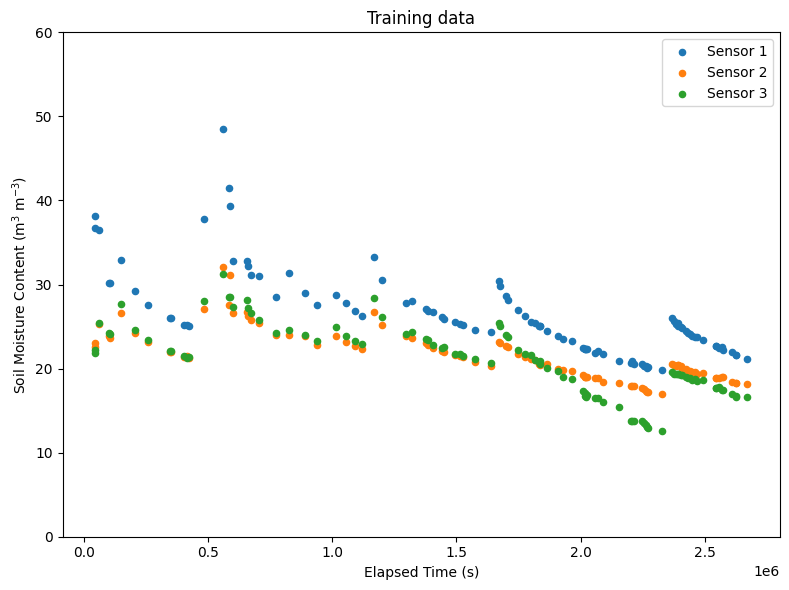

Plotting GP for Sensor 1


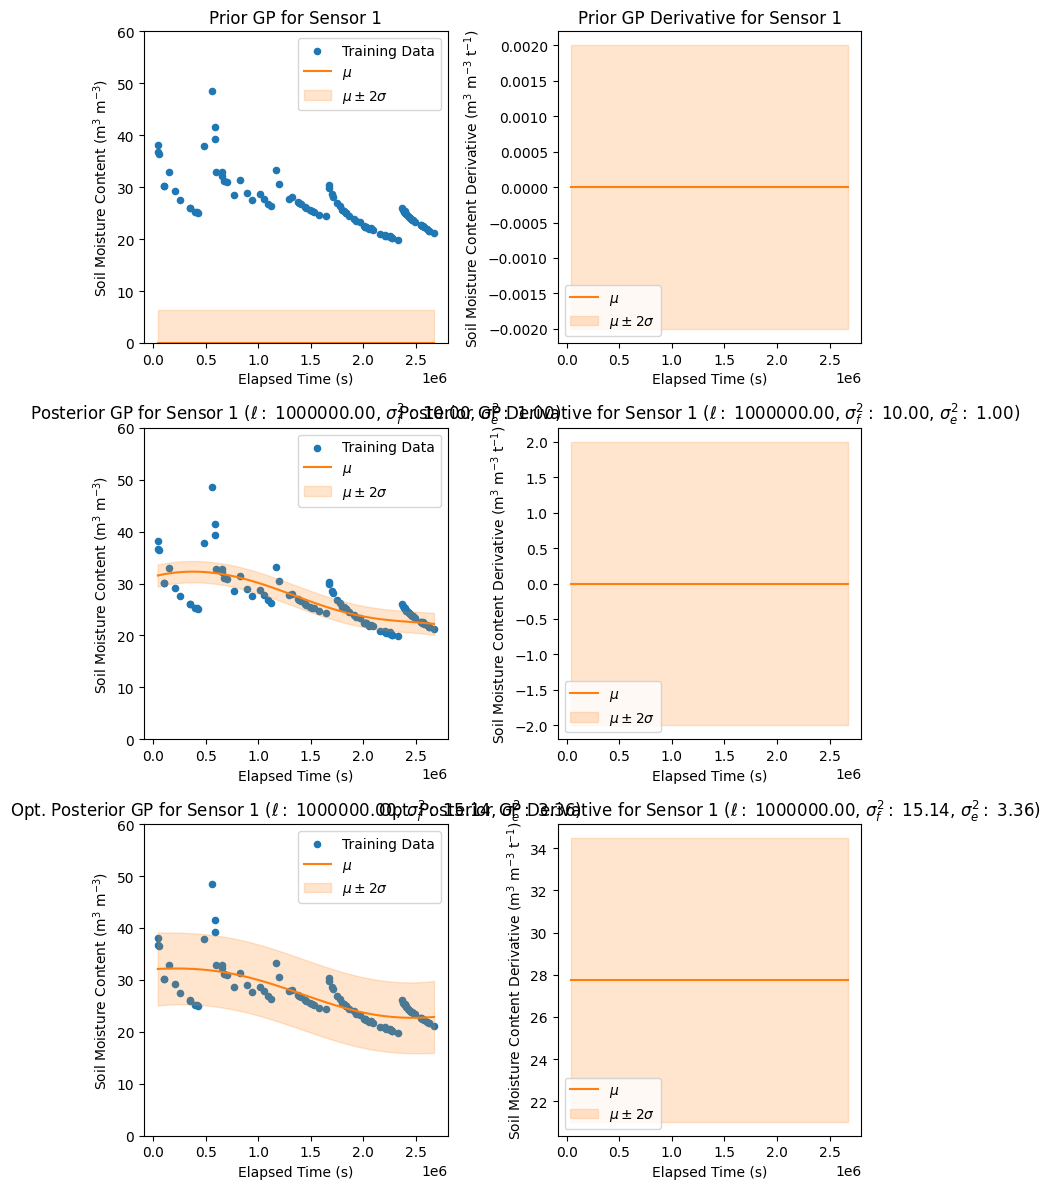

[Dataset(Number of observations: 100 - Input dimension: 2), Dataset(Number of observations: 100 - Input dimension: 2), Dataset(Number of observations: 100 - Input dimension: 2)]


In [47]:


########
# Main #
########

A = -0.1
B = -0.05
NUM_SAMPLES = 1000
NUM_TRAIN = 100
NUM_TEST = 100
INIT_GP_PARAMS = {
    "kernel": {
        "lengthscale": 1e6, 
        "variance": 10.0
    },
    "likelihood": {
        "variance": 1.0
    }
}
DATA_IDX = 0
rnd_key = jr.key(123)


print("Loading datasets")
dataset_dict, rnd_key = get_datasets(NUM_TRAIN, NUM_TEST, rnd_key)


print("Plotting training data")
cols = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
for i, dataset in enumerate(dataset_dict['train']):
    x, y = format_data_to_plot(dataset)
    ax.scatter(x, y, color=cols[i], label=f"Sensor {i+1}", s=20)
    format_standard_plot(ax)
    ax.set_title(f"Training data")
ax.legend()
plt.tight_layout()
plt.show()

prior, posterior, opt_posterior = fit_gp(dataset_dict['train'][DATA_IDX], INIT_GP_PARAMS)


opt_params = {
    "kernel": {
        "lengthscale": float(opt_posterior.prior.kernel.kernel.lengthscale.value.take(0)),
        "variance": float(opt_posterior.prior.kernel.kernel.variance.value.take(0))
    },
    "likelihood": {
        "variance": float(opt_posterior.likelihood.obs_stddev)
    }
}
# print(f"Initial GP Parameters: {INIT_GP_PARAMS}")
# print(f"Optimised GP Parameters: {opt_params}")


print(f"Plotting GP for Sensor {DATA_IDX+1}")
fig, axs = plt.subplots(3, 2, figsize=(8, 12))

x = dataset_dict['train'][DATA_IDX].X[:, 0]
x_test = np.linspace(x.min(), x.max(), 100)
x_test_gp = add_zeros_dim(x_test[:, None])

pred_dist_dict = get_gp_pred_dist(dataset_dict['train'][DATA_IDX], x_test_gp, 
                                    prior, posterior, opt_posterior)    


for i, (title, pred_dist_dict) in enumerate(pred_dist_dict.items()):
    mean = pred_dist_dict["mean"]
    std = pred_dist_dict["std"]
    x_train, y_train = format_data_to_plot(dataset_dict['train'][DATA_IDX])
    format_standard_plot(axs[i, 0])

    axs[i, 0].scatter(x_train, y_train, color=cols[0], label='Training Data', s=20)
    axs[i, 0].plot(x_test, mean, label='$\mu$', color=cols[1])
    axs[i, 0].fill_between(x_test, mean - 2 * std, mean + 2 * std, alpha=0.2, color=cols[1], label='$\mu \pm 2\sigma$')
    axs[i, 0].legend()

    if i == 1:
        l = INIT_GP_PARAMS['kernel']['lengthscale']
        v = INIT_GP_PARAMS['kernel']['variance']
        e = INIT_GP_PARAMS['likelihood']['variance']
    elif i == 2:
        l = opt_params['kernel']['lengthscale']
        v = opt_params['kernel']['variance']
        e = opt_params['likelihood']['variance']
    
    if i == 0:
        axs[i, 0].set_title(f"{title} GP for Sensor {DATA_IDX+1}")
    else:
        axs[i, 0].set_title(f"{title} GP for Sensor {DATA_IDX+1} ($\ell:$ {l:.2f}, $\sigma^2_f:$ {v:.2f}, $\sigma^2_e:$ {e:.2f})")

# plotting derivatives 
x_test_gp = add_ones_dim(x_test[:, None])
pred_dist_dict = get_gp_pred_dist(dataset_dict['train'][DATA_IDX], x_test_gp, 
                                    prior, posterior, opt_posterior)
for i, (title, pred_dist_dict) in enumerate(pred_dist_dict.items()):
    mean = pred_dist_dict["mean"]
    std = pred_dist_dict["std"]
    format_derivative_plot(axs[i, 1])


    axs[i, 1].plot(x_test, mean, label='$\mu$', color=cols[1])
    axs[i, 1].fill_between(x_test, mean - 2 * std, mean + 2 * std, alpha=0.2, color=cols[1], label='$\mu \pm 2\sigma$')
    axs[i, 1].legend()

    if i == 1:
        l = INIT_GP_PARAMS['kernel']['lengthscale']
        v = INIT_GP_PARAMS['kernel']['variance']
        e = INIT_GP_PARAMS['likelihood']['variance']
    elif i == 2:
        l = opt_params['kernel']['lengthscale']
        v = opt_params['kernel']['variance']
        e = opt_params['likelihood']['variance']
    
    if i == 0:
        axs[i, 1].set_title(f"{title} GP Derivative for Sensor {DATA_IDX+1}")
    else:
        axs[i, 1].set_title(f"{title} GP Derivative for Sensor {DATA_IDX+1} ($\ell:$ {l:.2f}, $\sigma^2_f:$ {v:.2f}, $\sigma^2_e:$ {e:.2f})")

plt.tight_layout()
plt.show()
print(dataset_dict['train'])



# print("Rejection Sampling")
# samples, rnd_key = rejection_sampling(dataset_dict['train'][DATA_IDX], 
#                                       opt_posterior, 
#                                       A, B, NUM_SAMPLES, dataset_dict['train'][DATA_IDX].X.max(),
#                                       rnd_key)

# mc_field_capacity = np.mean(samples)

# print(f"Number of Samples: {len(samples)}")
# print(f"Estimated Field Capacity: {mc_field_capacity}")

# print("Finished Script")}

